<a href="https://colab.research.google.com/github/uu-255/Fake-News-Detection-ML-Project/blob/main/CSC322Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

folder = '/content/drive/MyDrive/fakeNewsDatasets'

Mounted at /content/drive


In [ ]:

# Load the Celebrity and FakeNewsAMT datasets

import pandas as pd
from pathlib import Path

base = Path(folder)

# Read Celebrity dataset
celebrity = base / 'celebrityDataset'

fake_celebrity = []
real_celebrity = []

# Read fake news articles
for file in (celebrity / 'fake').iterdir():
    if file.suffix == '.txt':
        fake_celebrity.append(file.read_text())

# Read legitimate news articles
for file in (celebrity / 'legit').iterdir():
    if file.suffix == '.txt':
        real_celebrity.append(file.read_text())

# Combine articles and assign labels (1 = fake, 0 = real)
celebrity_df = pd.DataFrame({
    'text': fake_celebrity + real_celebrity,
    'label': [1] * len(fake_celebrity) + [0] * len(real_celebrity)
})

# Read FakeNewsAMT dataset
fakeNews = base / 'fakeNewsDataset'

fake_articles = []
real_articles = []

for file in (fakeNews / 'fake').iterdir():
    if file.suffix == '.txt':
        fake_articles.append(file.read_text())

for file in (fakeNews / 'legit').iterdir():
    if file.suffix == '.txt':
        real_articles.append(file.read_text())

# Combine articles and assign labels
fakeNews_df = pd.DataFrame({
    'text': fake_articles + real_articles,
    'label': [1] * len(fake_articles) + [0] * len(real_articles)
})

# Check the number of articles in each dataset
print("Celebrity:", celebrity_df.shape)
print(celebrity_df['label'].value_counts())

print("\nFakeNewsAMT:", fakeNews_df.shape)
print(fakeNews_df['label'].value_counts())


Celebrity: (500, 2)
label
1    250
0    250
Name: count, dtype: int64

FakeNewsAMT: (480, 2)
label
1    240
0    240
Name: count, dtype: int64


In [ ]:

# Data cleaning

# Remove missing text
celebrity_df = celebrity_df.dropna(subset=['text'])
fakeNews_df = fakeNews_df.dropna(subset=['text'])

# Remove extra spaces
celebrity_df['text'] = celebrity_df['text'].str.strip()
fakeNews_df['text'] = fakeNews_df['text'].str.strip()

# Remove empty articles
celebrity_df = celebrity_df[celebrity_df['text'] != '']
fakeNews_df = fakeNews_df[fakeNews_df['text'] != '']

# Remove duplicate articles
celebrity_df = celebrity_df.drop_duplicates(subset=['text'])
fakeNews_df = fakeNews_df.drop_duplicates(subset=['text'])

# Check the cleaned datasets
print("Celebrity:", celebrity_df.shape)
print(celebrity_df['label'].value_counts())

print("\nFakeNewsAMT:", fakeNews_df.shape)
print(fakeNews_df['label'].value_counts())


Celebrity: (500, 2)
label
1    250
0    250
Name: count, dtype: int64

FakeNewsAMT: (480, 2)
label
1    240
0    240
Name: count, dtype: int64


In [ ]:

# Train and evaluate Linear SVM

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Use FakeNewsAMT dataset
X = fakeNews_df['text']
y = fakeNews_df['label']

# Convert text into TF-IDF features and train SVM
svm_model = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('svm', LinearSVC(random_state=42))
])

# Five-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate accuracy
svm_scores = cross_val_score(
    svm_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Linear SVM Accuracy for each fold:")
print(svm_scores)

print("Average Accuracy:", svm_scores.mean())


Linear SVM Accuracy for each fold:
[0.46875    0.35416667 0.38541667 0.46875    0.34375   ]
Average Accuracy: 0.4041666666666667


In [ ]:

# Check the dataset before training

print("Dataset size:", fakeNews_df.shape)

print("\nLabels:")
print(fakeNews_df['label'].value_counts())

print("\nFirst fake article:")
print(fakeNews_df[fakeNews_df['label'] == 1]['text'].iloc[0][:300])

print("\nFirst legitimate article:")
print(fakeNews_df[fakeNews_df['label'] == 0]['text'].iloc[0][:300])

print("\nMissing text:", fakeNews_df['text'].isna().sum())


Dataset size: (480, 2)

Labels:
label
1    240
0    240
Name: count, dtype: int64

First fake article:
Alex Jones Vindicated in "Pizzagate" Controversy

"Alex Jones, purveyor of the independent investigative news website Infowars and host of The Alex Jones Show, has been vindicated in his claims regarding the so-called "Pizzagate" controversy. Jones and others uncovered evidence last year that top De

First legitimate article:
Alex Jones Apologizes for Promoting 'Pizzagate' Hoax

Alex Jones  a prominent conspiracy theorist and the host of a popular right-wing radio show  has apologized for helping to spread and promote the hoax known as Pizzagate. The admission on Friday by Mr. Jones  the host of "The Alex Jones Show" and

Missing text: 0


In [ ]:

# Compare unigram and unigram + bigram features

for n in [1, 2]:

    model = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, n))),
        ('svm', LinearSVC(random_state=42))
    ])

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring='accuracy'
    )

    print("N-gram range:", (1, n))
    print("Average accuracy:", scores.mean())


N-gram range: (1, 1)
Average accuracy: 0.43125
N-gram range: (1, 2)
Average accuracy: 0.4041666666666667


In [ ]:

# Train and evaluate Random Forest

from sklearn.ensemble import RandomForestClassifier

# TF-IDF + Random Forest
rf_model = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('rf', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Five-fold cross-validation
rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Random Forest Accuracy for each fold:")
print(rf_scores)

print("Average Accuracy:", rf_scores.mean())


Random Forest Accuracy for each fold:
[0.59375    0.52083333 0.58333333 0.55208333 0.59375   ]
Average Accuracy: 0.5687500000000001


In [ ]:

# Compare evaluation metrics for both models

from sklearn.model_selection import cross_validate
import pandas as pd

results = []

for name, model in [
    ('Linear SVM', svm_model),
    ('Random Forest', rf_model)
]:
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1']
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-score': scores['test_f1'].mean()
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.404,0.415,0.462,0.437
1,Random Forest,0.569,0.555,0.712,0.622


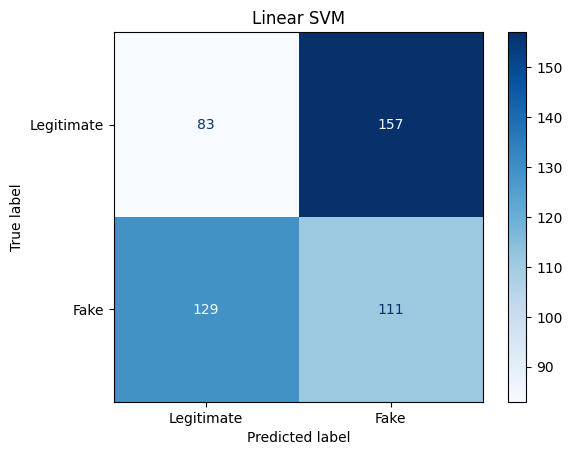

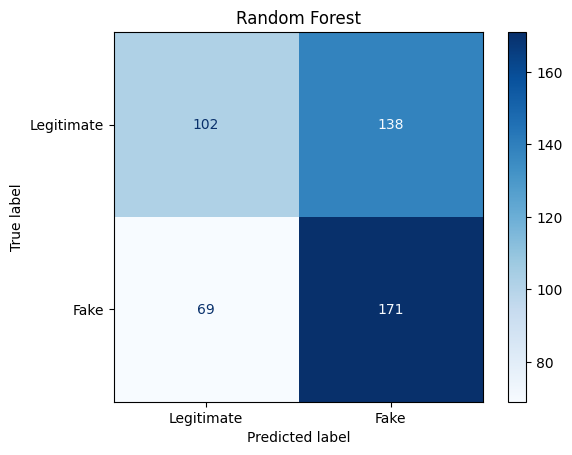

In [ ]:

# Confusion matrices for SVM and Random Forest

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in [
    ('Linear SVM', svm_model),
    ('Random Forest', rf_model)
]:
    predictions = cross_val_predict(
        model, X, y, cv=cv
    )

    cm = confusion_matrix(y, predictions, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Legitimate', 'Fake']
    ).plot(cmap='Blues')

    plt.title(name)
    plt.show()


In [ ]:
import time

# Measure SVM training and testing time
start_time = time.time()

from sklearn.model_selection import cross_validate

svm_times = cross_validate(
    svm_model,
    X,
    y,
    cv=cv,
    scoring='accuracy',
    return_train_score=True
)

print("SVM Average Training Time:", svm_times['fit_time'].mean(), "seconds")
print("SVM Average Testing Time:", svm_times['score_time'].mean(), "seconds")

# Random forest training and testing time
start_time = time.time()

rf_times = cross_validate(
    rf_model,
    X,
    y,
    cv=cv,
    scoring='accuracy',
    return_train_score=True
)
print("Random Forest Average Training Time:", rf_times['fit_time'].mean(), "seconds")
print("Random Forest Average Testing Time:", rf_times['score_time'].mean(), "seconds")


SVM Average Training Time: 0.1807406425476074 seconds
SVM Average Testing Time: 0.022541093826293945 seconds
Random Forest Average Training Time: 0.8193961143493652 seconds
Random Forest Average Testing Time: 0.036049699783325194 seconds


In [ ]:
#Comparing both models in a table

results = []

for name, model in [
    ('Linear SVM', svm_model),
    ('Random Forest', rf_model)
]:
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1'],
        return_train_score=True
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-score': scores['test_f1'].mean(),
        'Training Time (seconds)': scores['fit_time'].mean(),
        'Testing Time (seconds)': scores['score_time'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),
        'Precision Std': scores['test_precision'].std(),
        'Recall Std': scores['test_recall'].std(),
        'F1 Std': scores['test_f1'].std()
    })

# Create comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,Training Time (seconds),Testing Time (seconds),Accuracy Std,Precision Std,Recall Std,F1 Std
0,Linear SVM,0.4042,0.4148,0.4625,0.4373,0.2607,0.0420,0.0545,0.0473,0.0482,0.0475
1,Random Forest,0.5688,0.5555,0.7125,0.6223,0.9992,0.0584,0.0284,0.0265,0.0580,0.0232


In [ ]:

# Compare training and validation accuracy

from sklearn.model_selection import cross_validate

for name, model in [
    ('Linear SVM', svm_model),
    ('Random Forest', rf_model)
]:
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring='accuracy',
        return_train_score=True
    )

    print(name)
    print("Training Accuracy:",
          scores['train_score'].mean())
    print("Validation Accuracy:",
          scores['test_score'].mean())
    print()


Linear SVM
Training Accuracy: 1.0
Validation Accuracy: 0.4041666666666667

Random Forest
Training Accuracy: 1.0
Validation Accuracy: 0.5687500000000001



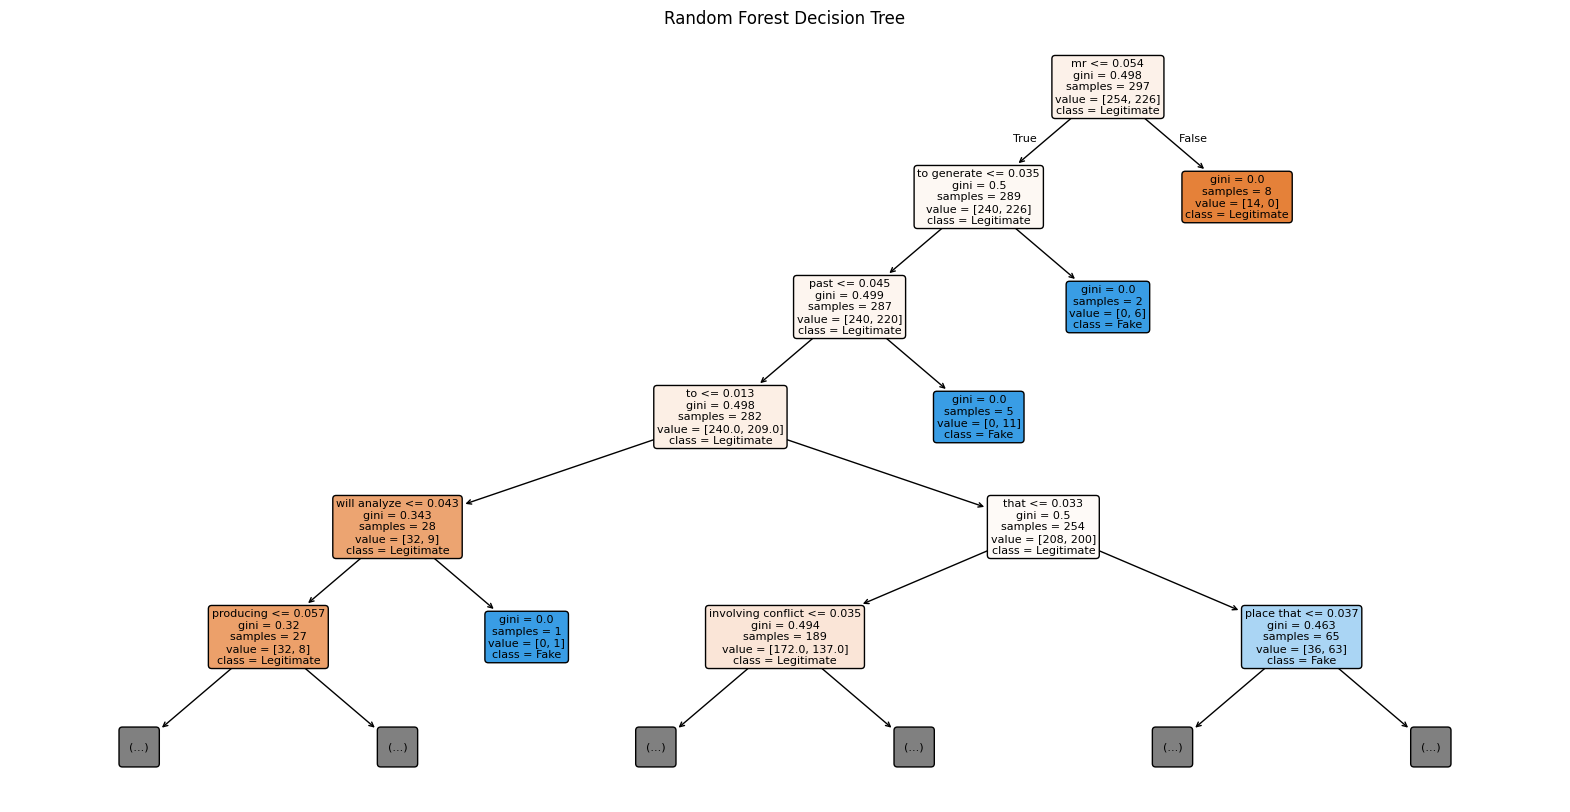

In [ ]:
# Decision Tree for Random Forest

rf_model.named_steps['rf']
rf_model.fit(X, y)

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Get the Random Forest classifier
forest = rf_model.named_steps['rf']

# Get the TF-IDF feature names
feature_names = rf_model.named_steps['tfidf'].get_feature_names_out()

# Visualize the first decision tree
plt.figure(figsize=(20, 10))

plot_tree(
    forest.estimators_[0],
    max_depth=5,
    feature_names=feature_names,
    class_names=['Legitimate', 'Fake'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Random Forest Decision Tree")
plt.show()